# FrameSignal Lab: Simulation Diagnostics
Known-truth target inference, household-preserving sensitivity, SQL integrity, and failure analysis. Synthetic evidence only. Fixed horizon and household randomization. Operating characteristics assess target inference, not surrogate certification.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'configs' / 'analysis_plan.json').exists())
sys.path.insert(0, str(root / 'backend'))
from app.analysis.workbench import PLAN, analyze, operating_characteristics
from app.metrics.registry import household_metrics
from app.simulations.generator import simulate
run = analyze('misleading', PLAN['households_per_experiment'], PLAN['seed'])
assert run['sql']['passed']
pd.Series(run['sql']['counts'])

registered_households         2000
households_without_viewing     431
missing_outcomes                 0
duplicate_households             0
orphan_events                    0
invalid_availability             0
invalid_watch_time               0
invalid_return_window            0
itt_left_join_count           2000
dtype: int64

In [2]:
sensitivity_rows = []
for row in run['diagnostics']['rows']:
    for metric, values in row['effects'].items():
        sensitivity_rows.append({'variant': row['label'], 'metric': metric, 'effect': values['effect'], 'lower': values['lower'], 'upper': values['upper'], 'note': row['note']})
pd.DataFrame(sensitivity_rows)

,variant,metric,effect,lower,upper,note
0,Days 0-13,qualified_starts,1.957000,1.714026,2.199974,Registered household denominator; unadjusted p...
1,Days 0-13,viewing_days,1.411000,1.243946,1.578054,Registered household denominator; unadjusted p...
2,Days 0-13,watch_minutes,22.775999,13.456099,32.095898,Registered household denominator; unadjusted p...
3,Days 0-6,qualified_starts,0.568000,0.471448,0.664552,Shorter window; all assigned households retained.
4,Days 0-6,viewing_days,0.456000,0.377190,0.534810,Shorter window; all assigned households retained.
5,Days 0-6,watch_minutes,4.160998,0.798232,7.523765,Shorter window; all assigned households retained.
6,Pooled 99th-percentile cap,qualified_starts,1.886180,1.663222,2.109138,Exploratory winsorization changes the estimand...
7,Pooled 99th-percentile cap,viewing_days,1.381000,1.219025,1.542975,Exploratory winsorization changes the estimand...
8,Pooled 99th-percentile cap,watch_minutes,22.601303,14.085785,31.116821,Exploratory winsorization changes the estimand...
9,Runtime <= 48 minutes,qualified_starts,1.104000,0.953924,1.254076,Event subset only; household denominator uncha...


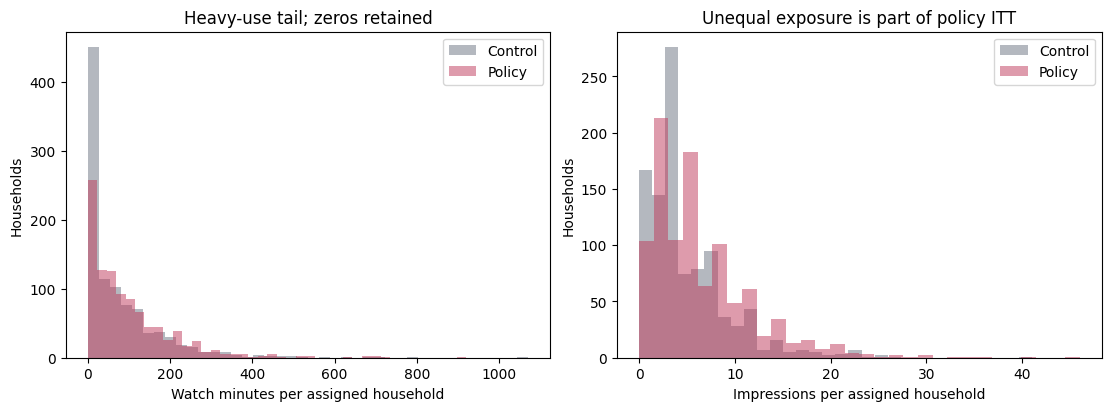

,bootstrap_sd,lower,upper
qualified_starts,0.130809,1.695000,2.222925
viewing_days,0.087356,1.241450,1.576525
watch_minutes,5.035768,12.426707,32.897614
returned_d29_56,0.021002,-0.082525,0.000575


In [3]:
data = simulate('misleading', PLAN['households_per_experiment'], PLAN['seed'])
households = household_metrics(data)
assert len(households) == PLAN['households_per_experiment']
assert households.loc[~households.starter, 'completion'].isna().all()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for arm, label, color in [(0, 'Control', '#6b7280'), (1, 'Policy', '#bf395a')]:
    group = households[households.assignment == arm]
    axes[0].hist(group.watch_minutes, bins=40, alpha=0.5, label=label, color=color)
    axes[1].hist(group.impressions, bins=30, alpha=0.5, label=label, color=color)
axes[0].set(xlabel='Watch minutes per assigned household', ylabel='Households', title='Heavy-use tail; zeros retained')
axes[1].set(xlabel='Impressions per assigned household', ylabel='Households', title='Unequal exposure is part of policy ITT')
for axis in axes:
    axis.legend()
plt.show()
pd.DataFrame(run['diagnostics']['sampling_variation']).T

In [4]:
operating = operating_characteristics(PLAN['seed'], PLAN['operating_repetitions'], PLAN['households_per_experiment'])
operating_rows = [{'truth_pp': 100 * row['true_effect'], 'coverage': row['coverage']['rate'], 'coverage_mc_low': row['coverage']['lower'], 'coverage_mc_high': row['coverage']['upper'], 'null_fpr_or_power': row['rejection_rate']['rate'], 'rejection_mc_low': row['rejection_rate']['lower'], 'rejection_mc_high': row['rejection_rate']['upper'], 'bias_pp': 100 * row['bias'], 'bias_mc_se_pp': 100 * row['bias_mc_se'], 'variance': row['sampling_variance'], 'mean_width_pp': 100 * row['mean_interval_width'], 'practical_success': row['practical_success']['rate']} for row in operating['rows']]
pd.DataFrame(operating_rows)

,truth_pp,coverage,coverage_mc_low,coverage_mc_high,null_fpr_or_power,rejection_mc_low,rejection_mc_high,bias_pp,bias_mc_se_pp,variance,mean_width_pp,practical_success
0,0.0,0.946,0.930208,0.958379,0.054,0.041621,0.069792,-0.0313,0.071107,0.000506,8.759445,0.001
1,2.0,0.944,0.927977,0.956625,0.177,0.154593,0.201879,0.1191,0.072610,0.000527,8.747955,0.038
2,4.0,0.931,0.913585,0.945116,0.438,0.407545,0.468930,-0.0100,0.074491,0.000555,8.727388,0.152
3,6.0,0.947,0.931325,0.959253,0.777,0.750168,0.801712,-0.0216,0.069504,0.000483,8.701016,0.432
4,10.0,0.945,0.929092,0.957503,0.994,0.986972,0.997247,-0.1489,0.071103,0.000506,8.628244,0.937


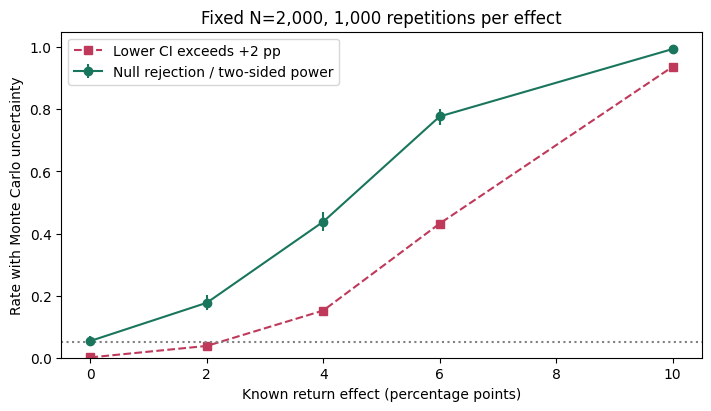

In [5]:
fig, axis = plt.subplots(figsize=(7, 4), constrained_layout=True)
effects_pp = [100 * row['true_effect'] for row in operating['rows']]
rates = [row['rejection_rate']['rate'] for row in operating['rows']]
lower_errors = [row['rejection_rate']['rate'] - row['rejection_rate']['lower'] for row in operating['rows']]
upper_errors = [row['rejection_rate']['upper'] - row['rejection_rate']['rate'] for row in operating['rows']]
axis.errorbar(effects_pp, rates, yerr=[lower_errors, upper_errors], fmt='o-', color='#19765c', label='Null rejection / two-sided power')
axis.plot(effects_pp, [row['practical_success']['rate'] for row in operating['rows']], 's--', color='#bf395a', label='Lower CI exceeds +2 pp')
axis.axhline(0.05, linestyle=':', color='gray')
axis.set(xlabel='Known return effect (percentage points)', ylabel='Rate with Monte Carlo uncertainty', ylim=(0, 1.05), title='Fixed N=2,000, 1,000 repetitions per effect')
axis.legend()
plt.show()

## Failure analysis
Heavy-use households, runtime, genre, windows, and unequal exposure can change short-term signals. Capping and per-impression normalization change estimands; post-assignment exposure normalization is not original ITT. Completion among starters remains selected, regardless of bootstrap precision. Coverage near 95% and null rejection near 5% under this target DGP do not validate a proxy. Small effects can have limited power at the predefined sample size, especially for a +2 pp confidence-bound decision. No significance-triggered stopping or outcome-based extension is allowed. Real attrition, interference, observational selection, and transportability are not simulated. Self-review only.

In [6]:
from pathlib import Path
import sys
import pandas as pd
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'configs' / 'analysis_plan.json').exists())
sys.path.insert(0, str(root / 'backend'))
from framesignal_metrics import __version__ as metric_library_version, calculate_household_metrics
from app.metrics.registry import household_metrics
from app.simulations.generator import simulate
parity_data = simulate('misleading', n=200, seed=21)
library_frame = calculate_household_metrics(parity_data.households, parity_data.events, parity_data.exposures, window=7)
pd.testing.assert_frame_equal(library_frame, household_metrics(parity_data, window=7), check_exact=True)
assert len(library_frame) == 200
assert library_frame.loc[~library_frame.starter, 'completion'].isna().all()
print(f'Shared library {metric_library_version}: exact 7-day parity; all 200 assigned households retained. Existing calibration flags remain unresolved scientific evidence.')

Shared library 1.0.0: exact 7-day parity; all 200 assigned households retained. Existing calibration flags remain unresolved scientific evidence.
